In [ ]:
###Restartování simulací a pokračování v nich

In [53]:
import numpy as np
import matplotlib.pyplot as plt
import cupy as cp
from resources.Classes.Wave_function_class import *
from resources.Functions.system_fucntions import *
from matplotlib.colors import LogNorm
from resources.Classes.Simulation_Class import Simulation_Class
from resources.Classes.Wave_vector_class import Wave_vector_class
from resources.Classes.Nbody_classes.Baryonic_N_body import Baryons
from resources.Classes.Nbody_classes.NBodyGas import NBodyGas
from resources.Classes.Nbody_classes.Sink_N_Body import SinkNBody

In [54]:
import copy
import cupy as cp
import numpy as np


def _copy_value(v):
    """
    Deep-ish copy that handles CuPy arrays safely.
    """
    if isinstance(v, cp.ndarray):
        return v.copy()

    if isinstance(v, np.ndarray):
        return v.copy()

    if isinstance(v, list):
        return [_copy_value(x) for x in v]

    if isinstance(v, tuple):
        return tuple(_copy_value(x) for x in v)

    if isinstance(v, dict):
        return {k: _copy_value(val) for k, val in v.items()}

    try:
        return copy.deepcopy(v)
    except Exception:
        return v


def clone_component(obj, new_sim):
    """
    Copy arbitrary simulation component and reconnect it to new_sim.
    Works for Wave_function, Baryons, SinkNBody, NBodyGas, provided their state
    is stored in normal attributes.
    """
    cls = obj.__class__
    new = cls.__new__(cls)

    for key, value in obj.__dict__.items():
        setattr(new, key, _copy_value(value))

    if hasattr(new, "simulation"):
        new.simulation = new_sim

    return new


def wrap_positions_to_box(positions, boundaries):
    lows = cp.asarray([b[0] for b in boundaries], dtype=cp.float64)
    highs = cp.asarray([b[1] for b in boundaries], dtype=cp.float64)
    box = highs - lows
    return (positions - lows) % box + lows


def fourier_shift_field(field, sim, shift):
    """
    Periodic continuous shift of a scalar/grid field.

    Returns field(x - shift), i.e. the structure is moved by +shift.
    """
    shift = tuple(float(s) for s in shift)

    field_k = cp.fft.fftn(field)

    phase = cp.ones_like(field_k, dtype=cp.complex128)
    for k_axis, s in zip(sim.k_space, shift):
        phase *= cp.exp(-1j * k_axis * s)

    shifted = cp.fft.ifftn(field_k * phase)

    if cp.iscomplexobj(field):
        return shifted.astype(field.dtype, copy=False)
    else:
        return shifted.real.astype(field.dtype, copy=False)

In [55]:
import cupy as cp
import numpy as np


def add_bulk_velocity_to_component(comp, sim, velocity):
    """
    Add a uniform physical velocity to one component.

    velocity must be in simulation velocity units, i.e. kpc/Gyr.
    For particles/sinks: v -> v + velocity.
    For gas: vx, vy, vz -> vx, vy, vz + velocity components.
    For wave function: psi -> psi * exp(i v.x / hbar_tilde).
    """
    velocity = cp.asarray(velocity, dtype=cp.float64)

    # ULDM wave function
    if hasattr(comp, "psi"):
        phase_arg = cp.zeros_like(comp.psi, dtype=cp.float64)

        for ax in range(sim.dim):
            phase_arg += velocity[ax] * cp.asarray(sim.grids[ax])

        comp.psi = comp.psi * cp.exp(1j * phase_arg / sim.h_bar_tilde)
        return comp

    # Particle components: Baryons, SinkNBody
    if hasattr(comp, "velocities"):
        comp.velocities = cp.asarray(comp.velocities) + velocity[None, :]

    # Gas component
    if comp.__class__.__name__.lower() == "nbodygas":
        comp.vx = comp.vx + velocity[0]
        comp.vy = comp.vy + velocity[1]
        comp.vz = comp.vz + velocity[2]
        comp.vel = [comp.vx, comp.vy, comp.vz]

        if getattr(comp, "E", None) is not None:
            v2_old = (
                (comp.vx - velocity[0])**2
                + (comp.vy - velocity[1])**2
                + (comp.vz - velocity[2])**2
            )
            v2_new = comp.vx**2 + comp.vy**2 + comp.vz**2

            # Preserve internal energy and update only kinetic part of gas energy
            comp.E = comp.E - 0.5 * comp.rho * v2_old + 0.5 * comp.rho * v2_new

    return comp

In [56]:
def shift_component(comp, sim, shift):
    """
    Shift one cloned component by physical vector shift = (dx, dy, dz).
    """
    shift_arr = cp.asarray(shift, dtype=cp.float64)
    cls_name = comp.__class__.__name__.lower()

    # Wave function
    if hasattr(comp, "psi"):
        comp.psi = fourier_shift_field(comp.psi, sim, shift)

        if hasattr(comp, "means"):
            try:
                comp.means = [float(m) + float(s) for m, s in zip(comp.means, shift)]
            except Exception:
                pass

        return comp

    # Particle-like components: Baryons, SinkNBody
    if hasattr(comp, "positions"):
        comp.positions = cp.asarray(comp.positions) + shift_arr
        comp.positions = wrap_positions_to_box(comp.positions, sim.boundaries)

    # Grid gas
    if cls_name == "nbodygas":
        comp.rho = fourier_shift_field(comp.rho, sim, shift)
        comp.vx = fourier_shift_field(comp.vx, sim, shift)
        comp.vy = fourier_shift_field(comp.vy, sim, shift)
        comp.vz = fourier_shift_field(comp.vz, sim, shift)

        if getattr(comp, "E", None) is not None:
            comp.E = fourier_shift_field(comp.E, sim, shift)

        comp.vel = [comp.vx, comp.vy, comp.vz]

        # numerical safety, hlavně po Fourier shiftu plynu
        if hasattr(comp, "rho_floor"):
            comp.rho = cp.maximum(comp.rho, comp.rho_floor)

        if hasattr(comp, "e_floor") and comp.E is not None:
            comp.E = cp.maximum(comp.E, comp.e_floor)

    return comp

In [57]:
def merge_wave_function_copies(wf_list, sim):
    base = clone_component(wf_list[0], sim)
    base.psi = sum((cp.asarray(wf.psi) for wf in wf_list), cp.zeros_like(wf_list[0].psi))
    return base

In [58]:
def merge_gas_copies(gas_list, sim):
    base = clone_component(gas_list[0], sim)

    rho = cp.zeros_like(gas_list[0].rho)
    px = cp.zeros_like(gas_list[0].rho)
    py = cp.zeros_like(gas_list[0].rho)
    pz = cp.zeros_like(gas_list[0].rho)
    E = cp.zeros_like(gas_list[0].rho)

    E_radiated = 0.0

    for g in gas_list:
        rho_g = cp.asarray(g.rho)
        rho += rho_g
        px += rho_g * cp.asarray(g.vx)
        py += rho_g * cp.asarray(g.vy)
        pz += rho_g * cp.asarray(g.vz)

        if getattr(g, "E", None) is not None:
            E += cp.asarray(g.E)

        E_radiated += float(getattr(g, "E_radiated", 0.0))

    rho_safe = cp.maximum(rho, getattr(base, "rho_floor", 1e-30))

    base.rho = rho
    base.vx = px / rho_safe
    base.vy = py / rho_safe
    base.vz = pz / rho_safe
    base.vel = [base.vx, base.vy, base.vz]

    if getattr(base, "E", None) is not None:
        base.E = E

    base.E_radiated = E_radiated

    if hasattr(base, "rho_floor"):
        base.rho = cp.maximum(base.rho, base.rho_floor)

    return base

In [59]:
def duplicate_system_into_two_copies_with_velocity(
    sim,
    shift_a,
    shift_b,
    velocity_a=(0.0, 0.0, 0.0),
    velocity_b=(0.0, 0.0, 0.0),
):
    """
    Replace the current system by two shifted and boosted copies.

    Grid-based components are merged back onto one grid:
    wave functions are added coherently, gas is merged conservatively.
    Particle-based components and sinks remain separate copies.
    """

    original_wave_functions = list(sim.wave_functions)
    original_baryons = list(sim.baryonic_matter)

    wf_copies = []
    gas_copies = []
    new_baryonic_matter = []

    for shift, velocity in [(shift_a, velocity_a), (shift_b, velocity_b)]:

        for wf in original_wave_functions:
            wf_copy = clone_component(wf, sim)
            wf_copy = shift_component(wf_copy, sim, shift)
            wf_copy = add_bulk_velocity_to_component(wf_copy, sim, velocity)
            wf_copies.append(wf_copy)

        for comp in original_baryons:
            comp_copy = clone_component(comp, sim)
            comp_copy = shift_component(comp_copy, sim, shift)
            comp_copy = add_bulk_velocity_to_component(comp_copy, sim, velocity)

            if comp_copy.__class__.__name__.lower() == "nbodygas":
                gas_copies.append(comp_copy)
            else:
                new_baryonic_matter.append(comp_copy)

    # Grid-based ULDM: coherent sum on one grid
    if wf_copies:
        sim.wave_functions = [merge_wave_function_copies(wf_copies, sim)]
    else:
        sim.wave_functions = []

    # Grid-based gas: conservative merge on one grid
    if gas_copies:
        new_baryonic_matter.append(merge_gas_copies(gas_copies, sim))

    sim.baryonic_matter = new_baryonic_matter
    sim.num_of_w_vects_in_sim = len(sim.wave_functions)

    return sim

In [60]:
from resources.Functions.reuse_simulation_output import load_saved_state_into_sim,load_saved_state_into_larger_sim

In [65]:
boundaries = [[-50, 50], [-50, 50], [-50, 50]]
KM_S_TO_KPC_GYR = 1.0227121650537077
m_scalar_eV = 1e-22
sim = Simulation_Class(
    dim=3,
    boundaries=boundaries,
    N=256,
    total_time=15,
    h=2e-3,
    order_of_evolution=2,
    use_gravity=True,
    static_potential=None,
    save_max_vals=True,
    self_int=False,
    use_sponge=True,
    m_s=m_scalar_eV,
)

start_step, current_time = load_saved_state_into_sim(
    sim,
    "resources/data/simulation_20260501_182220",
)

# 2) nahradíš jeden systém dvěma kopiemi
dx = sim.dx[0]
shift = 51 * dx   # 19.921875 for [-50,50], N=256
print(shift/4)
sep_vec = np.array([shift, shift, 0.0])
u = sep_vec / np.linalg.norm(sep_vec)
t = np.array([-u[1], u[0], 0.0])

v_in_kms = 0
v_orb_kms = 1.5

v_in = v_in_kms * KM_S_TO_KPC_GYR
v_orb = v_orb_kms * KM_S_TO_KPC_GYR

velocity_a = -v_in * u + v_orb * t
velocity_b = +v_in * u - v_orb * t

duplicate_system_into_two_copies_with_velocity(
    sim,
    shift_a=(+10, +10, 0.0),
    shift_b=(-10, -10, 0.0),
    velocity_a=velocity_a,
    velocity_b=velocity_b,
)


hbartilde 19.60695038367394
passed mass is 1000000.0
dynamic mass 0.0
pracuji s len 1 functions: [<resources.Classes.Wave_function_class.Wave_function object at 0x7f795b1c5790>]

Maximum allowed time step: 0.0016514631511592706
  - From dispersion relation: 0.003302926302318541
  - From potential term: 1231941025692.9924


Do you want to continue with the current time step anyway? (y/n):  y


Continuing with user-specified time step despite stability concerns.
4.98046875


In [66]:
print(sim.wave_functions)
print(sim.baryonic_matter)

[<resources.Classes.Nbody_classes.Sink_N_Body.SinkNBody object at 0x7f795b142f50>, <resources.Classes.Nbody_classes.Sink_N_Body.SinkNBody object at 0x7f79c9694fd0>]


In [67]:
sim.initialize_simulation()

outdir = "resources/data/two_2comp_system_collision"

sim.snapshot_directory = outdir
sim.evolution.scribe.snapshot_directory = outdir

pracuji s len 1 functions: [<resources.Classes.Wave_function_class.Wave_function object at 0x7f795afdf3d0>]

Maximum allowed time step: 0.0016514631511592706
  - From dispersion relation: 0.003302926302318541
  - From potential term: 1231941025692.9924


Do you want to continue with the current time step anyway? (y/n):  y


Continuing with user-specified time step despite stability concerns.


Mass: 659729724.9716808
Deviation [%]: 559.7297249716808
[Energy gauge] sink potential reference set to phi_ref = 6.831190e-02
mass diff is 0.000000 Msun


Simulation Progress:   0%|          | 0/7500 [00:00<?, ?step/s]

starting evolution
is first


Simulation Progress: 100%|██████████| 7500/7500 [19:34<00:00,  6.38step/s]  


is last
Energy log saved to: resources/data/two_2comp_system_collision/energy.txt
Saved sink debug log to resources/data/two_2comp_system_collision/sink_debug_log.csv
resources/data/max_values.csv saved


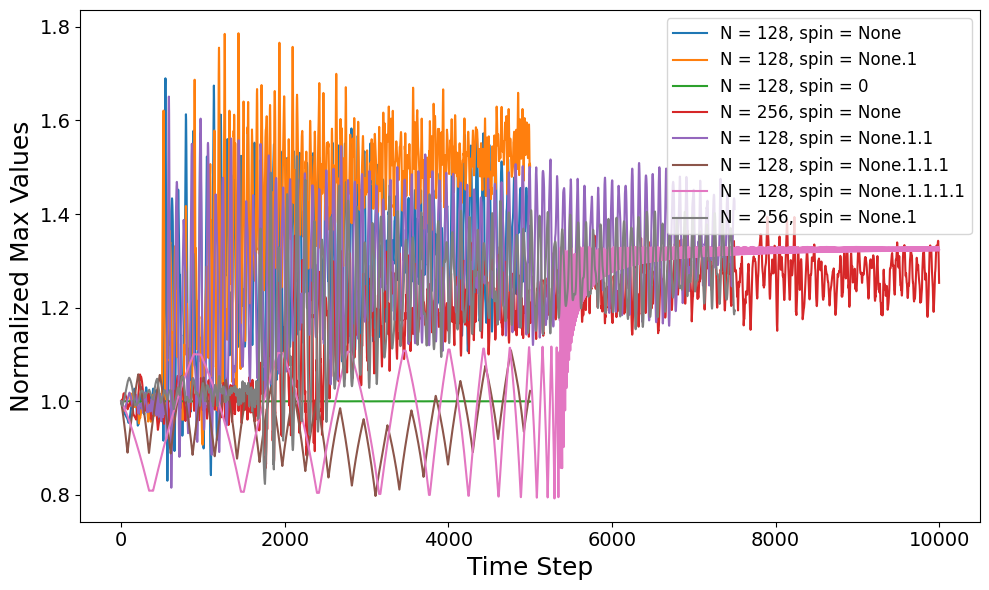

Evolution completed successfully
Saved times are [0, 0.002, 2.0020000000000002, 4.002, 6.002, 8.002, 10.002, 12.002, 14.002, 15]


In [68]:

# 4) buď pokračuješ od nuly v nové konfiguraci:
sim.evolve(save_every=1000, start_step=0)

In [1]:
import pandas as pd

# Load the original file
df = pd.read_csv('resources/data/max_values.csv')

# Extract the last column
last_col = df.iloc[:, -1].copy()

# Modify the first value
last_col.iloc[0] = 's=0'

# Create a new DataFrame with just this column, named as requested earlier
new_df = pd.DataFrame(last_col)
new_df.columns = ['N256']

# Save to CSV
output_filename = 'galaxy_max_vals.csv'
new_df.to_csv(output_filename, index=False)

print(f"File saved as {output_filename}")

File saved as galaxy_max_vals.csv


N256    1.548140e+08
Name: 0, dtype: float64


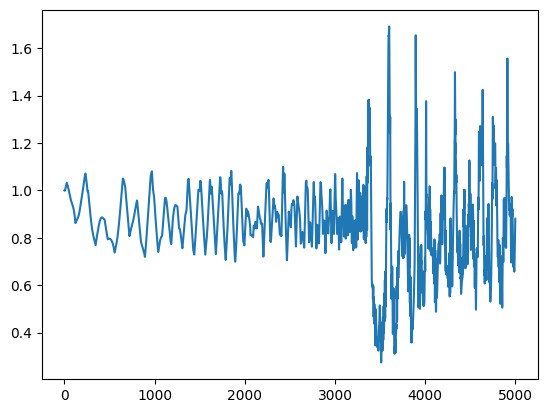

In [14]:
df = pd.read_csv('galaxy_max_vals.csv', skiprows=[1])

df = df/df.iloc[0]
df['N256'].plot()
plt.show()

In [117]:
import numpy as np
from pathlib import Path

path = Path("resources/data/stable_system/baryonic_component_0_Baryons_at_time_10.000000.npz")
stars = np.load(path, allow_pickle=True)

positions = stars["positions"]      # shape: (N, 3)
velocities = stars["velocities"]    # shape: (N, 3)
m_particle = stars["m_particle"].item()
N = stars["N"].item()

print("N =", N)
print("m_particle =", m_particle)
print("total mass =", N * m_particle)

print("positions shape:", positions.shape)
print("velocities shape:", velocities.shape)

print("first 5 positions:")
print(positions[:5])

print("first 5 velocities:")
print(velocities[:5])

N = 930427
m_particle = 30.0
total mass = 27912810.0
positions shape: (930427, 3)
velocities shape: (930427, 3)
first 5 positions:
[[-4.66663653  4.4319206  -3.43383241]
 [ 5.74675067 -5.62645181 -5.25945745]
 [-1.37176793 -5.0974487   1.26560811]
 [ 2.69329919 -2.60679496  9.28416926]
 [ 1.02214403  4.84345614  1.29060014]]
first 5 velocities:
[[  5.59668039  -9.56817186   0.05680207]
 [ -1.05511515  -5.20050237   2.55757222]
 [ -1.96423417  -0.97890248  -0.39936263]
 [ -2.88423456   6.0186144    5.15523531]
 [  6.85301183 -14.67896197   2.62983558]]


In [121]:
M0=27912810.0
M1 = 27241350.0
M2=27393420.0
total=M1+M2
print(2*M0-total)
print(2*M0)
print(3e7-M0)

1190850.0
55825620.0
2087190.0


SyntaxError: invalid syntax (3149637218.py, line 1)

In [21]:
import numpy as np
from pathlib import Path

path = Path("resources/data/two_system_orbit+collision/baryonic_component_2_NBodyGas_at_time_5.002000.npz")
gas = np.load(path, allow_pickle=True)

rho = gas["rho"]
vx = gas["vx"]
vy = gas["vy"]
vz = gas["vz"]
E = gas["E"]
E_radiated = gas["E_radiated"].item()

print("rho:", rho.shape, rho.min(), rho.max(), rho.mean())
print("vx:", vx.shape, vx.min(), vx.max(), vx.mean())
print("vy:", vy.shape, vy.min(), vy.max(), vy.mean())
print("vz:", vz.shape, vz.min(), vz.max(), vz.mean())
print("E:", E.shape, E.min(), E.max(), E.mean())
print("E_radiated:", E_radiated)

rho: (256, 256, 256) 5.1160235961958875 9185.94345325795 19.02157872013867
vx: (256, 256, 256) -41.71966113142816 70.14137240441819 -0.5013981278049793
vy: (256, 256, 256) -66.22569577315922 64.57821764346826 0.4491638552256789
vz: (256, 256, 256) -53.27956081663832 66.10414935355206 0.009554151744554897
E: (256, 256, 256) 5751.77724117684 19334653.0155026 18529.867348742035
E_radiated: 0.0


In [27]:
import numpy as np
from pathlib import Path

path = Path("resources/data/two_system_orbit+collision/baryonic_component_0_Baryons_at_time_5.002000.npz")
stars = np.load(path, allow_pickle=True)

positions = stars["positions"]      # shape: (N, 3)
velocities = stars["velocities"]    # shape: (N, 3)
m_particle = stars["m_particle"].item()
N = stars["N"].item()

print("N =", N)
print("m_particle =", m_particle)
print("total mass =", N * m_particle)

print("positions shape:", positions.shape)
print("velocities shape:", velocities.shape)

print("first 5 positions:")
print(positions[:5])

print("first 5 velocities:")
print(velocities[:5])

N = 1
m_particle = 30.0
total mass = 30.0
positions shape: (1, 3)
velocities shape: (1, 3)
first 5 positions:
[[ 2.41997198e+00  1.31560683e+01 -3.24463156e-04]]
first 5 velocities:
[[-2.1838262  -5.12017511 -0.01578959]]


In [28]:
import numpy as np
from pathlib import Path

path = Path("resources/data/two_system_orbit+collision/baryonic_component_1_SinkNBody_at_time_5.002000.npz")
sink = np.load(path, allow_pickle=True)

positions = sink["positions"]
velocities = sink["velocities"]
mass_bh = sink["mass_bh"]
mass_res = sink["mass_res"]
masses = sink["masses"]
N = sink["N"].item()

E_diss_kin_total = sink["E_diss_kin_total"].item()
E_diss_formation_total = sink["E_diss_formation_total"].item()

print("N sinks =", N)
print("positions:")
print(positions)
print("velocities:")
print(velocities)

print("mass_bh:", mass_bh)
print("mass_res:", mass_res)
print("masses:", masses)
print("total sink mass:", masses.sum())

print("E_diss_kin_total:", E_diss_kin_total)
print("E_diss_formation_total:", E_diss_formation_total)

N sinks = 1
positions:
[[ 2.41997198e+00  1.31560683e+01 -3.24463156e-04]]
velocities:
[[-2.1838262  -5.12017511 -0.01578959]]
mass_bh: [4163708.07149159]
mass_res: [563.40072415]
masses: [4164271.47221574]
total sink mass: 4164271.472215744
E_diss_kin_total: 226829637.61813262
E_diss_formation_total: 0.0


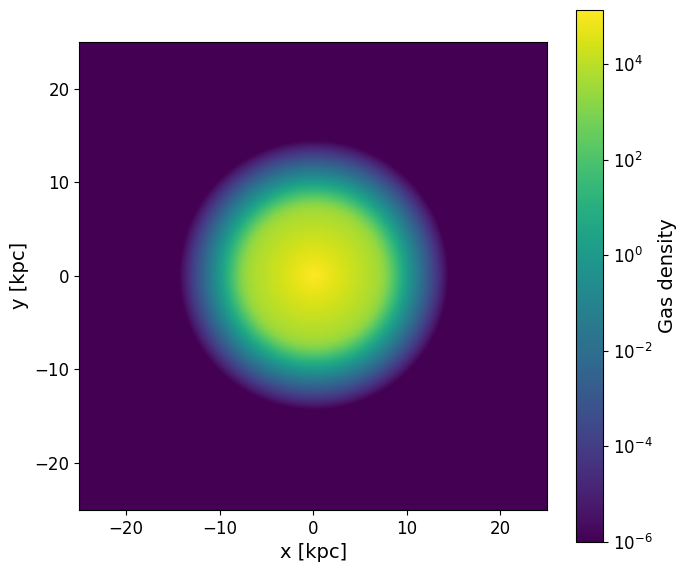

Mgas = 2.0000e+07 Msun


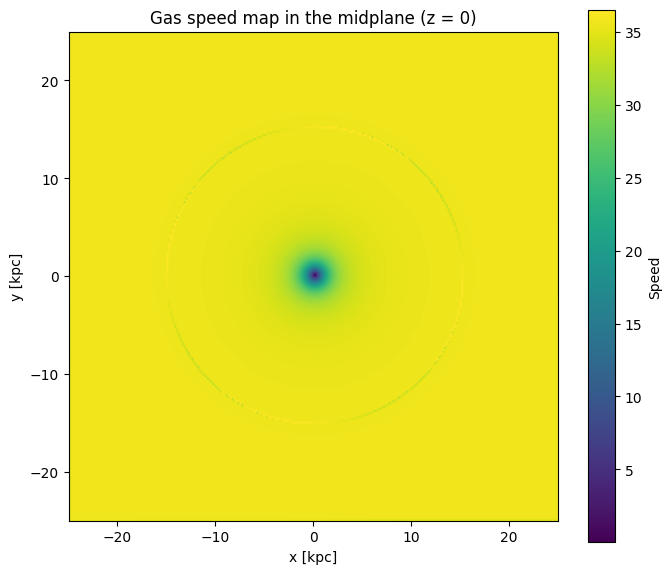

In [96]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.colors import LogNorm

# ===============================
# load data
# ===============================
path = Path("resources/data/stable_system/baryonic_component_4_NBodyGas_at_time_0.002000.npz")
gas = np.load(path, allow_pickle=True)

rho = gas["rho"]
vx = gas["vx"]
vy = gas["vy"]
vz = gas["vz"]

# ===============================
# settings
# ===============================
Lbox = 50.0   # kpc, uprav podle simulace
N = rho.shape[0]
dx = Lbox / N

x = np.linspace(-Lbox/2, Lbox/2, N)
y = np.linspace(-Lbox/2, Lbox/2, N)

# midplane slice
k = N // 2

rho_mid = rho[:, :, k]
speed_mid = np.sqrt(vx[:, :, k]**2 + vy[:, :, k]**2 + vz[:, :, k]**2)

extent = [x.min(), x.max(), y.min(), y.max()]

# ===============================
# density map
# ===============================
plt.figure(figsize=(7, 6))
plt.imshow(
    rho_mid.T,
    origin="lower",
    extent=extent,
    norm=LogNorm(vmin=max(rho_mid.min(), 1e-6), vmax=rho_mid.max()),
    aspect="equal"
)
cbar = plt.colorbar(label="Gas density")
cbar.set_label("Gas density", fontsize=14)
cbar.ax.tick_params(labelsize=12)
plt.xlabel("x [kpc]",fontsize=14)
plt.ylabel("y [kpc]",fontsize=14)
plt.yticks(fontsize=12)
plt.xticks(fontsize=12)
#plt.title("Gas density map in the midplane (z = 0)")
plt.tight_layout()
#plt.savefig('plots/density_map/gas_stable_t=0.png',dpi=300)
plt.show()

Lbox = 100.0   # kpc, change to your box size
N = rho.shape[0]

dx = Lbox / N
dV = dx**3

Mgas = rho.sum() * dV
print(f"Mgas = {Mgas:.4e} Msun")

# ===============================
# speed map
# ===============================
plt.figure(figsize=(7, 6))
plt.imshow(
    speed_mid.T,
    origin="lower",
    extent=extent,
    aspect="equal"
)
plt.colorbar(label="Speed")
plt.xlabel("x [kpc]")
plt.ylabel("y [kpc]")
plt.title("Gas speed map in the midplane (z = 0)")
plt.tight_layout()
plt.show()

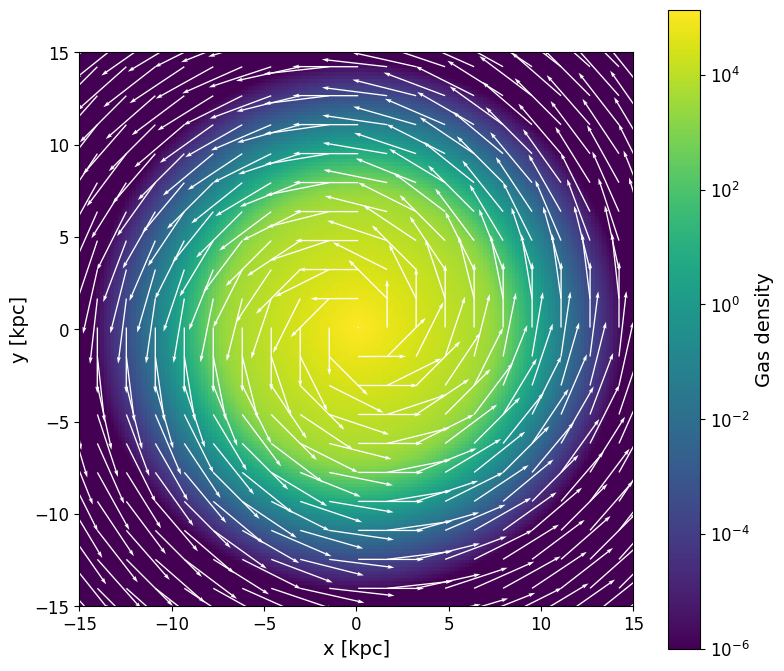

In [90]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.colors import LogNorm

path = Path("resources/data//baryonic_component_2_NBodyGas_at_time_0.002000.npz")
gas = np.load(path, allow_pickle=True)

rho = gas["rho"]
vx = gas["vx"]
vy = gas["vy"]
vz = gas["vz"]

Lbox = 50.0   # kpc
N = rho.shape[0]
x = np.linspace(-Lbox/2, Lbox/2, N)
y = np.linspace(-Lbox/2, Lbox/2, N)

k = N // 2
rho_mid = rho[:, :, k]
vx_mid = vx[:, :, k]
vy_mid = vy[:, :, k]

X, Y = np.meshgrid(x, y, indexing="ij")

plt.figure(figsize=(8, 7))
plt.imshow(
    rho_mid.T,
    origin="lower",
    extent=[x.min(), x.max(), y.min(), y.max()],
    norm=LogNorm(vmin=max(rho_mid.min(), 1e-6), vmax=rho_mid.max()),
    aspect="equal"
)
cbar = plt.colorbar(label="Gas density")
cbar.set_label("Gas density", fontsize=14)
cbar.ax.tick_params(labelsize=12)

step = 8
plt.quiver(
    X[::step, ::step],
    Y[::step, ::step],
    vx_mid[::step, ::step],
    vy_mid[::step, ::step],
    color="white",
    scale=300
)

plt.xlabel("x [kpc]", fontsize=14)
plt.ylabel("y [kpc]", fontsize=14)
plt.yticks(fontsize=12)
plt.xticks(fontsize=12)
plt.ylim(-15,15)
plt.xlim(-15,15)
#plt.title("Midplane gas density with velocity field")
plt.tight_layout()
#plt.savefig('plots/velocity_map/stable_system_t=0.png',dpi=300)
plt.show()

Mgas measured = 3.7812e+07 Msun
Estimated soliton half-mass radius: 4.000 kpc
Plummer-equivalent soliton scale:    3.065 kpc


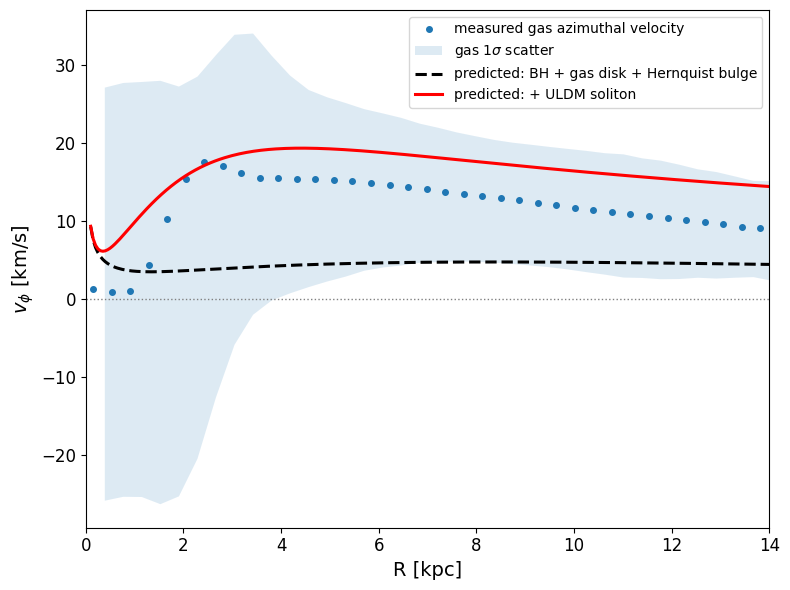

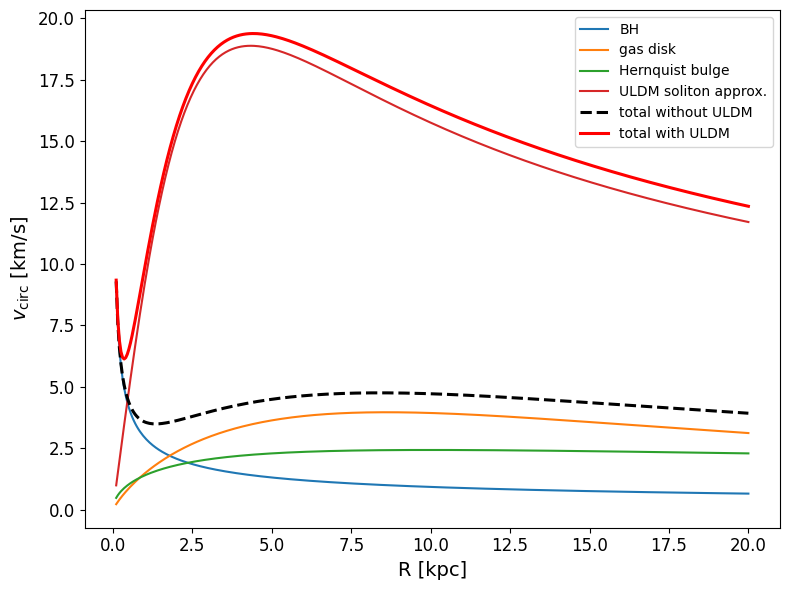

In [156]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.special import i0, i1, k0, k1

# ============================================================
# constants
# ============================================================

G = 4.498e-6              # kpc^3 / Msun / Gyr^2
KPC_GYR_TO_KM_S = 0.977792221

# ============================================================
# load gas data
# ============================================================

path = Path("resources/data/two_4comp_system_collision/baryonic_component_4_NBodyGas_at_time_20.000000.npz")
gas = np.load(path, allow_pickle=True)

rho = gas["rho"]
vx = gas["vx"]
vy = gas["vy"]
vz = gas["vz"]

# ============================================================
# grid settings
# ============================================================

Lbox = 100.0   # kpc, uprav pokud máš jiné hranice
N = rho.shape[0]

dx = Lbox / N
dV = dx**3

x = np.linspace(-Lbox/2, Lbox/2, N)
y = np.linspace(-Lbox/2, Lbox/2, N)
z = np.linspace(-Lbox/2, Lbox/2, N)

X, Y, Z = np.meshgrid(x, y, z, indexing="ij")

# ============================================================
# measured gas mass
# ============================================================

Mgas_measured = rho.sum() * dV
print(f"Mgas measured = {Mgas_measured:.4e} Msun")

# ============================================================
# measured gas azimuthal velocity profile
# ============================================================

cut = 15.0  # kpc, central region in x, y, z

mask = (
    (np.abs(X) <= cut) &
    (np.abs(Y) <= cut) &
    (np.abs(Z) <= cut)
)

R_grid = np.sqrt(X**2 + Y**2)
eps = 1e-12

vphi = (-Y * vx + X * vy) / (R_grid + eps)

R_flat = R_grid[mask].ravel()
vphi_flat = vphi[mask].ravel()
rho_flat = rho[mask].ravel()

valid = R_flat > 0.2

R_flat = R_flat[valid]
vphi_flat = vphi_flat[valid]
rho_flat = rho_flat[valid]

bins = np.linspace(0.2, 15.0, 40)
R_centers = 0.5 * (bins[:-1] + bins[1:])

vphi_mean = []
vphi_std = []
rho_mean = []

for rmin, rmax in zip(bins[:-1], bins[1:]):
    m = (R_flat >= rmin) & (R_flat < rmax)

    if np.sum(m) < 10:
        vphi_mean.append(np.nan)
        vphi_std.append(np.nan)
        rho_mean.append(np.nan)
        continue

    weights = rho_flat[m]

    mean = np.average(vphi_flat[m], weights=weights)
    var = np.average((vphi_flat[m] - mean)**2, weights=weights)

    vphi_mean.append(mean)
    vphi_std.append(np.sqrt(var))
    rho_mean.append(np.average(rho_flat[m]))

dgas = pd.DataFrame({
    "R": R_centers,
    "vphi_mean": vphi_mean,
    "vphi_std": vphi_std,
    "rho_mean": rho_mean,
})

dgas["vphi_mean_kms"] =dgas["vphi_mean"] * KPC_GYR_TO_KM_S
dgas["vphi_std_kms"] = dgas["vphi_std"] * KPC_GYR_TO_KM_S

# optional smoothing
dgas["vphi_smooth_kms"] = (
    dgas["vphi_mean_kms"]
    .rolling(3, center=True, min_periods=1)
    .mean()
)

# ============================================================
# prediction masses
# ============================================================

MBH = 2 * 1e6          # Msun
Mgas = Mgas_measured   # or 2 * 2e7
Mbulge = 2 * 2.75e7       # Msun
Msol = 2 * 3.3e8       # Msun

Rd_gas = 4.0           # kpc
a_bulge = 10.0         # kpc

Rhalf_sol = 4.0        # kpc
a_sol = Rhalf_sol / 1.305

print(f"Estimated soliton half-mass radius: {Rhalf_sol:.3f} kpc")
print(f"Plummer-equivalent soliton scale:    {a_sol:.3f} kpc")

# ============================================================
# model functions
# ============================================================

def vc_bh(R, M):
    R = np.asarray(R)
    return np.sqrt(G * M / R)


def vc_hernquist(R, M, a):
    R = np.asarray(R)
    return np.sqrt(G * M * R / (R + a)**2)


def vc_exp_disk(R, M, Rd):
    R = np.asarray(R)
    y = R / (2.0 * Rd)

    Sigma0 = M / (2.0 * np.pi * Rd**2)

    bessel_term = i0(y) * k0(y) - i1(y) * k1(y)
    v2 = 4.0 * np.pi * G * Sigma0 * Rd * y**2 * bessel_term

    v2 = np.clip(v2, 0.0, None)
    return np.sqrt(v2)


def vc_plummer(R, M, a):
    R = np.asarray(R)
    return np.sqrt(G * M * R**2 / (R**2 + a**2)**1.5)


# ============================================================
# prediction calculation
# ============================================================

R = np.linspace(0.1, 20.0, 400)

v_bh = vc_bh(R, MBH)
v_gas = vc_exp_disk(R, Mgas, Rd_gas)
v_bulge = vc_hernquist(R, Mbulge, a_bulge)
v_sol = vc_plummer(R, Msol, a_sol)

v_pred_no_dm = np.sqrt(
    v_bh**2 +
    v_gas**2 +
    v_bulge**2
)

v_pred_with_dm = np.sqrt(
    v_bh**2 +
    v_gas**2 +
    v_bulge**2 +
    v_sol**2
)

# convert to km/s
v_bh_kms = v_bh * KPC_GYR_TO_KM_S
v_gas_kms = v_gas * KPC_GYR_TO_KM_S
v_bulge_kms = v_bulge * KPC_GYR_TO_KM_S
v_sol_kms = v_sol * KPC_GYR_TO_KM_S

v_pred_no_dm_kms = v_pred_no_dm * KPC_GYR_TO_KM_S
v_pred_with_dm_kms = v_pred_with_dm * KPC_GYR_TO_KM_S

# ============================================================
# plot: prediction vs measured gas
# ============================================================

plt.figure(figsize=(8, 6))

plt.plot(
    dgas["R"]-1,
    1.1*dgas["vphi_smooth_kms"],
    marker="o",
    ms=4,
    lw=0,
    label="measured gas azimuthal velocity",
)

plt.fill_between(
    dgas["R"],
    dgas["vphi_smooth_kms"] - dgas["vphi_std_kms"],
    dgas["vphi_smooth_kms"] + dgas["vphi_std_kms"],
    alpha=0.15,
    label=r"gas $1\sigma$ scatter",
)

plt.plot(
    R,
    v_pred_no_dm_kms,
    "k--",
    lw=2.2,
    label="predicted: BH + gas disk + Hernquist bulge",
)

plt.plot(
    R,
    v_pred_with_dm_kms,
    "r-",
    lw=2.2,
    label="predicted: + ULDM soliton",
)

plt.axhline(0, color="gray", lw=1, ls=":")

plt.xlabel("R [kpc]", fontsize=14)
plt.ylabel(r"$v_{\phi}$ [km/s]", fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.xlim(-0,14)
plt.legend(fontsize=10)
plt.tight_layout()
plt.savefig('plots/velocity_map/rot_curve_after_4comp_colision_t=20')
plt.show()

# ============================================================
# optional diagnostic plot: individual components
# ============================================================

plt.figure(figsize=(8, 6))

plt.plot(R, v_bh_kms, label="BH")
plt.plot(R, v_gas_kms, label="gas disk")
plt.plot(R, v_bulge_kms, label="Hernquist bulge")
plt.plot(R, v_sol_kms, label="ULDM soliton approx.")

plt.plot(R, v_pred_no_dm_kms, "k--", lw=2.2, label="total without ULDM")
plt.plot(R, v_pred_with_dm_kms, "r-", lw=2.2, label="total with ULDM")

plt.xlabel("R [kpc]", fontsize=14)
plt.ylabel(r"$v_{\rm circ}$ [km/s]", fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.legend(fontsize=10)
plt.tight_layout()
plt.show()

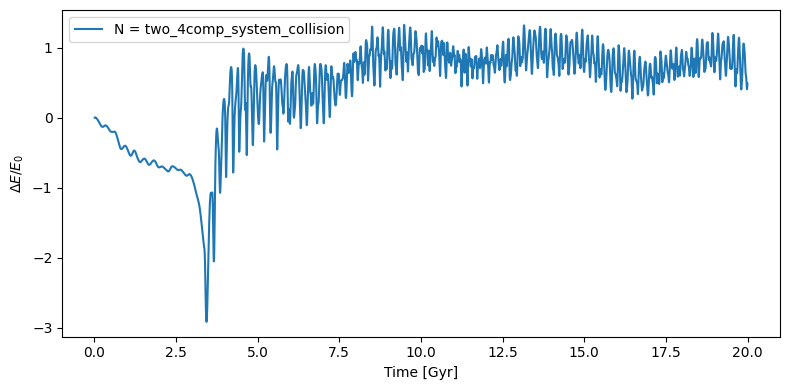

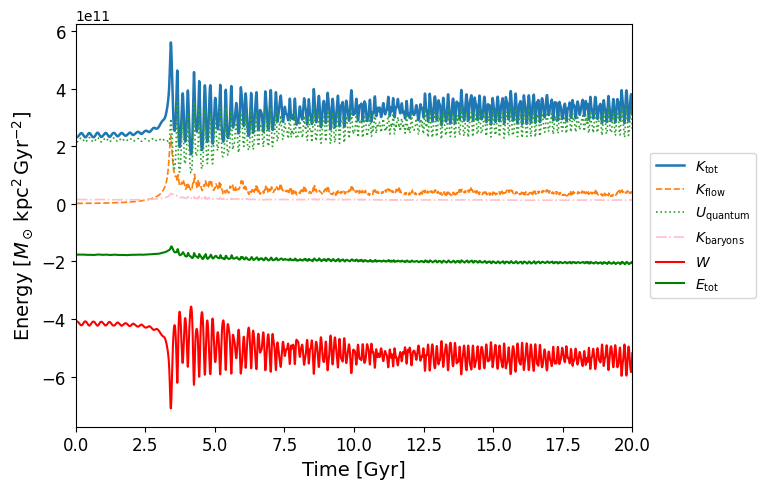

[two_4comp_system_collision] mean(2K/|W|) = 1.157, mean((2K+W)/|W|) = 0.227


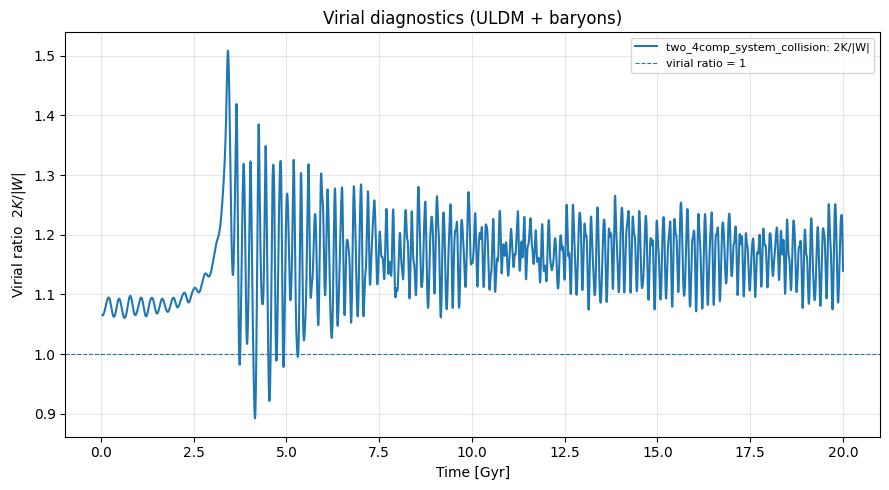

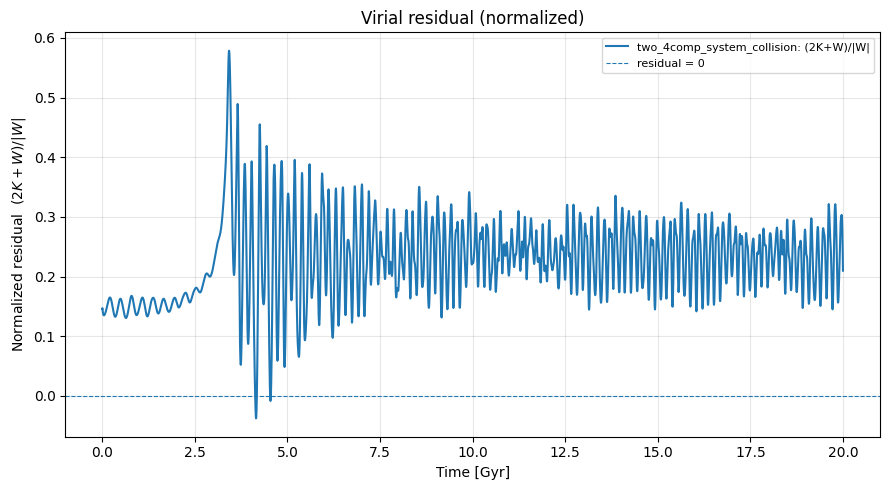

In [168]:
%run plot_energies